# Лабораторная работа №3. Решающее дерево

**Цель:** провести исследование решающего дерева (CART) на задачах классификации (Dota 2) и регрессии (шахматный эндшпиль KRKPA7): бейзлайн `sklearn`, улучшение через проверку гипотез, собственная реализация и сравнение (пункты 2–4 ЛР №1).

Наборы данных, постановка задач и обоснование метрик — в разделе 1 ЛР №1 (`lab1_knn.ipynb`). Метрики: классификация — **ROC-AUC** (основная), accuracy, F1; регрессия — **R²** (основная), RMSE, MAE.

## 0. Подготовка окружения

Импортируем библиотеки и общий пакет `mllab` из корня репозитория. В `mllab` лежат:
загрузчики данных (`mllab.data`), генераторы признаков (`mllab.features`), функции подсчёта метрик и журнал результатов (`mllab.metrics`), а также собственные реализации алгоритмов (`mllab.knn`, `mllab.linear`, `mllab.tree`, `mllab.forest`, `mllab.boosting`).
Предупреждения отключаем, чтобы не засорять вывод; для `Pipeline` включаем дисковый кэш (`.cache/`), чтобы тяжёлые преобразования признаков не пересчитывались в каждом прогоне кросс-валидации.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import inspect

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Code, display
from joblib import Memory
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler

import mllab
from mllab.data import RANDOM_STATE, load_chess, load_dota
from mllab.features import ChessFeatures, DotaFeatures
from mllab.metrics import ResultsLog, compare_cv, cv_report, evaluate

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_colwidth", 120)
memory = Memory(ROOT / ".cache", verbose=0)

Загружаем данные (подробное описание и обоснование выбора — в разделе 1 ЛР №1):
* **классификация** — *Dota 2 Games Results*: используем официальное разбиение UCI на train (92 650 матчей) и test (10 294 матча); целевая переменная `1` — победила команда 1;
* **регрессия** — *Chess KR vs KP (KRKPA7)*: стратифицированное разбиение 80/20 (`random_state=42`); целевая переменная `1.0` — белые выигрывают, `0.0` — нет; модель предсказывает непрерывную «оценку позиции».

Гиперпараметры подбираем только на train через 5-кратную кросс-валидацию (`StratifiedKFold` для классификации, `KFold` для регрессии); test используется только для финальной оценки.

In [2]:
X_cls_train, X_cls_test, y_cls_train, y_cls_test = load_dota()
X_reg_train, X_reg_test, y_reg_train, y_reg_test = load_chess()

cv_cls = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Классификация (Dota 2):", X_cls_train.shape, X_cls_test.shape)
print("Регрессия (шахматы KRKPA7):", X_reg_train.shape, X_reg_test.shape)

log = ResultsLog(lab=3, algorithm="DecisionTree")

Классификация (Dota 2): (92650, 116) (10294, 116)
Регрессия (шахматы KRKPA7): (2556, 36) (640, 36)


## 2. Создание бейзлайна и оценка качества

Бейзлайн — `DecisionTreeClassifier` и `DecisionTreeRegressor` из `sklearn` с параметрами по умолчанию (критерии `gini` / `squared_error`, дерево растёт до чистых листьев, `random_state=42`). Классификатор обучается на исходных признаках Dota 2, регрессор — на закодированных `ChessFeatures` признаках.

In [3]:
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

baseline_cls = DecisionTreeClassifier(random_state=RANDOM_STATE)
baseline_reg = make_pipeline(ChessFeatures(), DecisionTreeRegressor(random_state=RANDOM_STATE))

log.add("classification", "sklearn baseline",
        evaluate(baseline_cls, X_cls_train, y_cls_train, X_cls_test, y_cls_test, "classification"))
log.add("regression", "sklearn baseline",
        evaluate(baseline_reg, X_reg_train, y_reg_train, X_reg_test, y_reg_test, "regression"))
tree_reg = baseline_reg.named_steps["decisiontreeregressor"]
print(f"Dota: глубина = {baseline_cls.get_depth()}, листьев = {baseline_cls.get_n_leaves()}")
print(f"Шахматы: глубина = {tree_reg.get_depth()}, листьев = {tree_reg.get_n_leaves()}")
display(log.table("classification"), log.table("regression"))

Dota: глубина = 126, листьев = 23915
Шахматы: глубина = 13, листьев = 46


,roc_auc,accuracy,f1,fit_time,predict_time
variant,,,,,
sklearn baseline,0.5181,0.5193,0.5435,3.2355,0.0239


,r2,rmse,mae,fit_time,predict_time
variant,,,,,
sklearn baseline,0.9875,0.0559,0.0031,0.0099,0.0027


<!-- lab3_baseline -->
**Вывод по бейзлайну.**
* *Классификация:* полностью выращенное дерево для Dota 2 имеет глубину 126 и ≈24 тыс. листьев — оно запомнило обучающую выборку (по листу почти на каждые 4 матча). На test это даёт ROC-AUC = 0.518 и accuracy = 0.519 — хуже константного прогноза: дерево с чистыми листьями выдаёт «уверенные» вероятности 0/1, и ROC-AUC почти не отличается от случайного.
* *Регрессия:* на шахматах дерево — почти идеальная модель: R² = 0.9875, MAE = 0.003 при глубине 13 и всего 46 листьях. Разметка детерминирована и является логической функцией признаков, а дерево и есть набор логических правил. Суммарная квадратичная ошибка на test соответствует ≈2 неверно оценённым позициям из 640.

## 3. Улучшение бейзлайна

### 3.1. Гипотезы

**Классификация (Dota 2):**
* **H1. Ограничение глубины.** Полностью выращенное дерево запоминает шум обучающей выборки; ограничение `max_depth` должно уменьшить переобучение.
* **H2. Минимальный размер листа.** Крупные листья (`min_samples_leaf`) дают устойчивые оценки вероятности победы вместо 0/1 в чистых листьях — это особенно важно для ROC-AUC.
* **H3. Новые признаки.** Дерево делает разбиения по одному признаку, а сигнал в индикаторах героев слабый и «размазан» по 113 признакам. Агрегированные признаки драфта (win rate, синергия, контрпики) концентрируют сигнал в нескольких признаках, по которым дереву удобно делать разбиения.
* **H4. Критерий разбиения**: `gini` vs `entropy`.
* **H5. Совместный подбор гиперпараметров** на кросс-валидации.

**Регрессия (шахматы):**
* **H1. Ограничение глубины / размера листа.** Проверим, есть ли переобучение у полного дерева.
* **H2. Попарные взаимодействия признаков** (как в ЛР №2) — могут дать дереву готовые «составные» условия.
* **H3. Совместный подбор гиперпараметров** на кросс-валидации.

### 3.2. Проверка гипотез для классификации

**H1.** Строим кривые ROC-AUC на обучающих фолдах и на валидации в зависимости от максимальной глубины дерева.

,cv_mean,cv_std,train_mean,fit_time
candidate,,,,
2,0.5294,0.0028,0.5306,0.1694
4,0.5399,0.0022,0.5442,0.2414
6,0.5492,0.0031,0.5602,0.3621
8,0.5566,0.0030,0.5761,0.3802
10,0.5572,0.0036,0.5921,0.4764
14,0.5564,0.0049,0.6339,0.8715
20,0.5497,0.0058,0.7177,1.2650
None,0.5163,0.0024,1.0000,3.0963


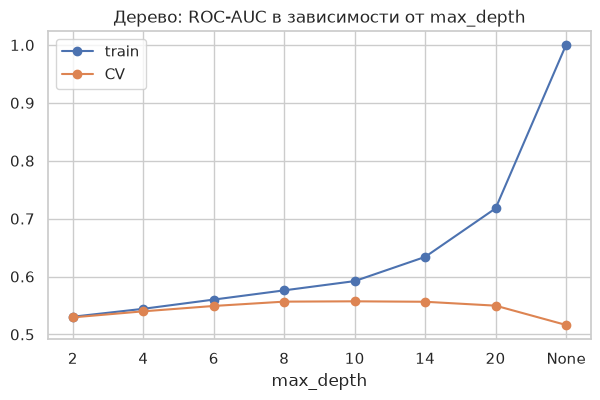

In [4]:
depths = [2, 4, 6, 8, 10, 14, 20, None]
h1_cls = compare_cv({
    str(d): DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE) for d in depths
}, X_cls_train, y_cls_train, cv_cls, "roc_auc")
ax = h1_cls[["train_mean", "cv_mean"]].plot(marker="o", figsize=(7, 4),
                                           title="Дерево: ROC-AUC в зависимости от max_depth")
ax.set_xlabel("max_depth")
ax.legend(["train", "CV"])
h1_cls

<!-- lab3_h1_cls -->
**H1 подтверждена.** Кривые показывают классическую картину переобучения: ROC-AUC на обучающих фолдах растёт с глубиной до 1.0, а на валидации достигает максимума 0.557 при глубине 8–10 и падает до 0.516 у полного дерева.

**H2.** Фиксируем глубину 10 и меняем минимальное число объектов в листе.

In [5]:
h2_cls = compare_cv({
    msl: DecisionTreeClassifier(max_depth=10, min_samples_leaf=msl, random_state=RANDOM_STATE)
    for msl in [1, 20, 100, 300, 1000, 2000]
}, X_cls_train, y_cls_train, cv_cls, "roc_auc")
h2_cls

,cv_mean,cv_std,train_mean,fit_time
candidate,,,,
1,0.5572,0.0036,0.5921,0.5126
20,0.5580,0.0027,0.5843,0.4411
100,0.5587,0.0035,0.5764,0.4346
300,0.5611,0.0034,0.5720,0.3863
1000,0.5594,0.0048,0.5653,0.3934
2000,0.5593,0.0033,0.5628,0.3598


<!-- lab3_h2_cls -->
**H2 подтверждена.** Ограничение размера листа дополнительно повышает ROC-AUC на CV: с 0.5572 (лист ≥ 1) до 0.5611 (лист ≥ 300), разрыв train/CV сокращается с 0.035 до 0.011. Крупные листья дают устойчивые оценки доли побед вместо 0/1.

**H3.** Сравниваем исходные признаки, индикаторы героев + статистики драфта и только 7 статистик драфта (дерево глубины 6 с листьями не меньше 1000 объектов).

In [6]:
def tree_on(features):
    return make_pipeline(features, DecisionTreeClassifier(max_depth=6, min_samples_leaf=1000,
                                                          random_state=RANDOM_STATE))

h3_cls = compare_cv({
    "исходные признаки": DecisionTreeClassifier(max_depth=6, min_samples_leaf=1000, random_state=RANDOM_STATE),
    "индикаторы + статистики": tree_on(DotaFeatures(meta="drop", drop_constant=True, synergy=True)),
    "только статистики (7 признаков)": tree_on(DotaFeatures(meta="drop", heroes="none", synergy=True)),
}, X_cls_train, y_cls_train, cv_cls, "roc_auc")
h3_cls

,cv_mean,cv_std,train_mean,fit_time
candidate,,,,
исходные признаки,0.5493,0.0034,0.5526,0.2844
индикаторы + статистики,0.6343,0.0038,0.6722,6.6924
только статистики (7 признаков),0.6344,0.0037,0.6729,6.0293


<!-- lab3_h3_cls -->
**H3 подтверждена — главный эффект.** Признаки драфта поднимают ROC-AUC на CV с 0.549 до 0.634 (+0.085) при той же структуре дерева. Добавлять к ним индикаторы героев бессмысленно (0.6343 против 0.6344): дерево всё равно выбирает для разбиений статистики драфта. Используем только 7 компактных признаков.

**H4 и H5.** Совместно подбираем критерий, глубину и размер листа на компактных признаках драфта.

In [7]:
pipe_cls = Pipeline([
    ("features", DotaFeatures(meta="drop", heroes="none", synergy=True)),
    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE)),
], memory=memory)
search_cls = GridSearchCV(pipe_cls, {
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [4, 6, 8, 12],
    "model__min_samples_leaf": [300, 1000, 2000],
}, cv=cv_cls, scoring="roc_auc", n_jobs=-1).fit(X_cls_train, y_cls_train)
print("Лучшие параметры:", search_cls.best_params_)
cv_report(search_cls)

Лучшие параметры: {'model__criterion': 'entropy', 'model__max_depth': 6, 'model__min_samples_leaf': 2000}


,model__criterion,model__max_depth,model__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
0,entropy,6,2000,0.6345,0.0038,1
1,gini,6,2000,0.6345,0.0041,2
2,gini,12,2000,0.6345,0.0042,3
3,gini,8,2000,0.6345,0.0042,3
4,entropy,8,2000,0.6344,0.0039,5
5,entropy,12,2000,0.6344,0.0039,5
6,gini,6,1000,0.6344,0.0037,7
7,entropy,6,1000,0.6342,0.0034,8
8,entropy,12,1000,0.6332,0.0036,9
9,entropy,8,1000,0.6331,0.0035,10


<!-- lab3_h45_cls -->
**H4 не подтверждена, H5 — оптимум найден.** Критерий разбиения не влияет на качество: `gini` и `entropy` дают одинаковый ROC-AUC 0.6345. Лучшая конфигурация — `entropy`, глубина 6, лист ≥ 2000 объектов; десяток конфигураций отличаются меньше чем на 0.0003 при разбросе по фолдам 0.004, т. е. на компактных признаках дерево выходит на плато. На визуализации ниже видно, что дерево сначала делит матчи по разнице win rate команд (`wr_diff`), а затем уточняет оценку по контрпикам (`counter`): при `wr_diff > 0.104` команда 1 выигрывает в 62 % матчей, а при `wr_diff ≤ −0.212` — только в 35 %.

Визуализируем верхние уровни лучшего дерева: видно, по каким признакам драфта модель принимает решения.

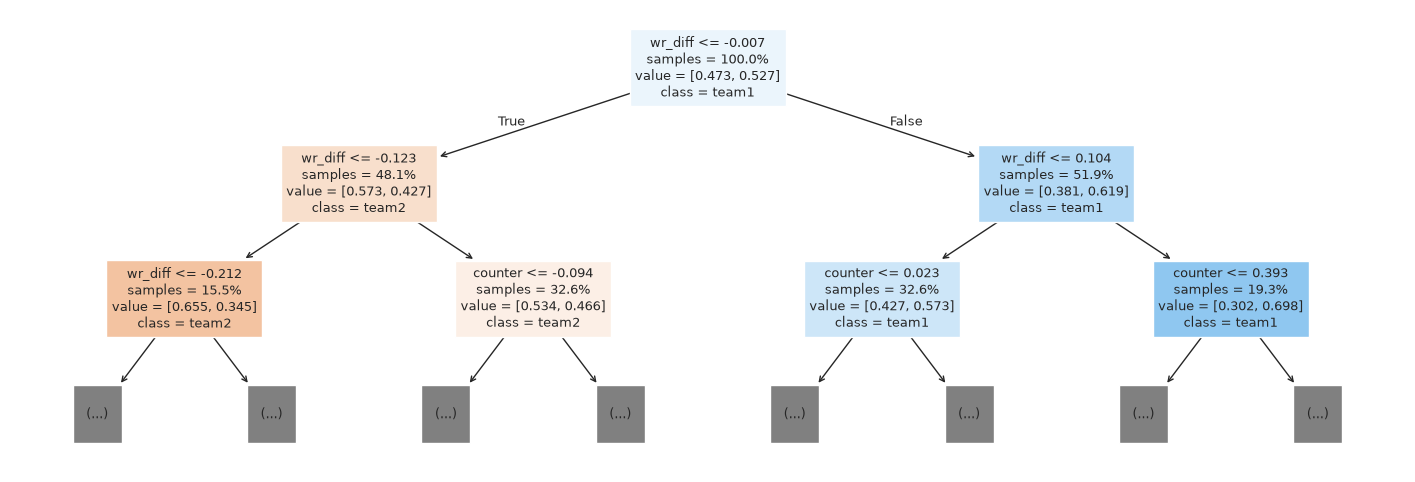

In [8]:
best_tree = search_cls.best_estimator_.named_steps["model"]
names = list(search_cls.best_estimator_.named_steps["features"].get_feature_names_out())
plt.figure(figsize=(18, 6))
plot_tree(best_tree, max_depth=2, feature_names=names, class_names=["team2", "team1"],
          filled=True, impurity=False, proportion=True, fontsize=9)
plt.show()

### 3.3. Проверка гипотез для регрессии

**H1.** Сравниваем полное дерево с ограниченными по глубине и размеру листа (R² на кросс-валидации и на обучающих фолдах).

In [9]:
h1_reg = compare_cv({
    "полное дерево": make_pipeline(ChessFeatures(), DecisionTreeRegressor(random_state=RANDOM_STATE)),
    **{f"max_depth={d}": make_pipeline(ChessFeatures(), DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE))
       for d in [4, 8, 12]},
    **{f"min_samples_leaf={m}": make_pipeline(ChessFeatures(),
                                              DecisionTreeRegressor(min_samples_leaf=m, random_state=RANDOM_STATE))
       for m in [2, 5]},
}, X_reg_train, y_reg_train, cv_reg, "r2")
h1_reg

,cv_mean,cv_std,train_mean,fit_time
candidate,,,,
полное дерево,0.9812,0.0094,1.0000,0.0176
max_depth=4,0.7910,0.0344,0.7933,0.0148
max_depth=8,0.9474,0.0027,0.9567,0.0176
max_depth=12,0.9783,0.0062,0.9966,0.0191
min_samples_leaf=2,0.9754,0.0111,0.9939,0.0206
min_samples_leaf=5,0.9514,0.0074,0.9759,0.0216


<!-- lab3_h1_reg -->
**H1 не подтверждена.** Любое ограничение дерева ухудшает качество: глубина 4 — R² 0.791, глубина 8 — 0.947, глубина 12 — 0.978, лист ≥ 5 — 0.951, против 0.981 у полного дерева. Переобучаться дереву не на чем: в разметке нет шума, и каждый «лишний» лист описывает реальное правило эндшпиля.

**H2.** Добавляем попарные взаимодействия признаков.

In [10]:
h2_reg = compare_cv({
    "исходные признаки": make_pipeline(ChessFeatures(), DecisionTreeRegressor(random_state=RANDOM_STATE)),
    "+ взаимодействия": make_pipeline(ChessFeatures(interactions=True),
                                      DecisionTreeRegressor(random_state=RANDOM_STATE)),
}, X_reg_train, y_reg_train, cv_reg, "r2")
h2_reg

,cv_mean,cv_std,train_mean,fit_time
candidate,,,,
исходные признаки,0.9812,0.0094,1.0000,0.0215
+ взаимодействия,0.9796,0.0117,1.0000,0.0885


<!-- lab3_h2_reg -->
**H2 не подтверждена.** Попарные взаимодействия не помогают дереву (R² 0.980 против 0.981): конъюнкции условий дерево и так строит последовательными разбиениями, а 703 дополнительных признака лишь увеличивают шанс выбрать случайно хорошее разбиение.

**H3.** Совместный подбор глубины, размера листа и минимального размера узла для разбиения.

In [11]:
pipe_reg = Pipeline([("features", ChessFeatures()), ("model", DecisionTreeRegressor(random_state=RANDOM_STATE))])
search_reg = GridSearchCV(pipe_reg, {
    "model__max_depth": [10, 15, 20, None],
    "model__min_samples_leaf": [1, 2, 3],
    "model__min_samples_split": [2, 4, 8],
}, cv=cv_reg, scoring="r2", n_jobs=-1).fit(X_reg_train, y_reg_train)
print("Лучшие параметры:", search_reg.best_params_)
cv_report(search_reg)

Лучшие параметры: {'model__max_depth': 15, 'model__min_samples_leaf': 1, 'model__min_samples_split': 4}


,model__max_depth,model__min_samples_leaf,model__min_samples_split,mean_test_score,std_test_score,rank_test_score
0,15,1,4,0.9822,0.0110,1
1,20,1,4,0.9822,0.0110,1
2,None,1,4,0.9822,0.0110,1
3,15,1,2,0.9812,0.0094,4
4,20,1,2,0.9812,0.0094,4
5,None,1,2,0.9812,0.0094,4
6,15,1,8,0.9809,0.0081,7
7,20,1,8,0.9809,0.0081,7
8,None,1,8,0.9809,0.0081,7
9,20,2,4,0.9754,0.0111,10


<!-- lab3_h3_reg -->
**H3.** Лучшая конфигурация по CV — `min_samples_split = 4` (R² 0.9822 против 0.9812 у бейзлайна); ограничение глубины 15/20 эквивалентно отсутствию ограничения (дерево и так имеет глубину 13). Прирост в 10 раз меньше разброса по фолдам (0.011) — по сути, параметры по умолчанию уже оптимальны. На визуализации ниже видны первые правила: если `rimmx = t` — белые выигрывают всегда (455 позиций), если `bxqsq = t` — не выигрывают никогда (599 позиций).

Визуализируем верхние уровни дерева для шахматного эндшпиля — это интерпретируемые правила оценки позиции.

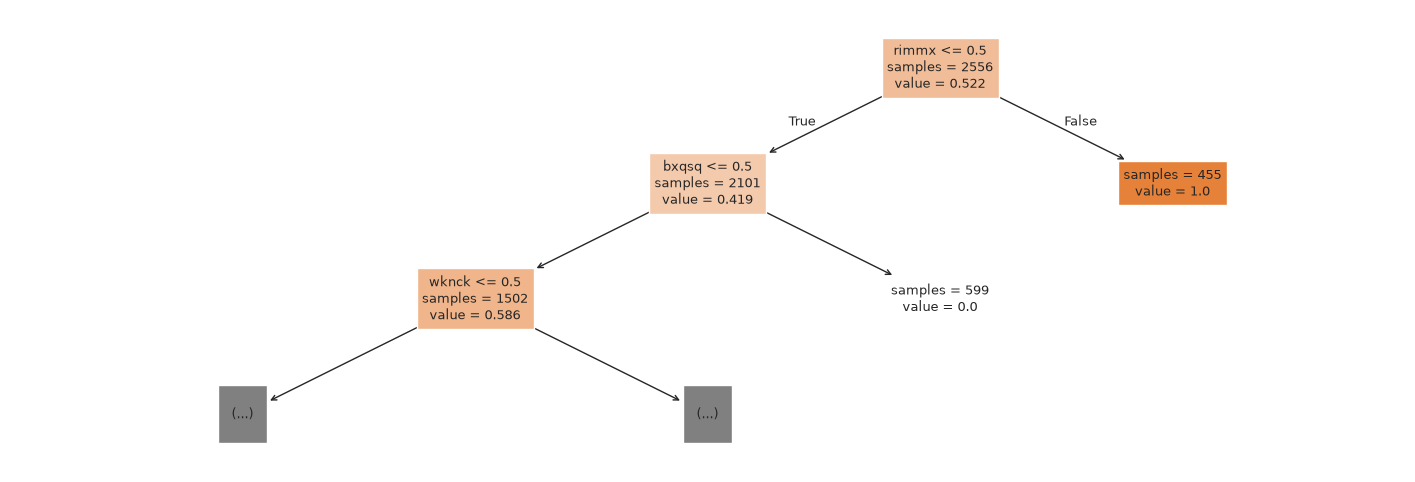

In [12]:
reg_tree = search_reg.best_estimator_.named_steps["model"]
reg_names = list(search_reg.best_estimator_.named_steps["features"].get_feature_names_out())
plt.figure(figsize=(18, 6))
plot_tree(reg_tree, max_depth=2, feature_names=reg_names, filled=True, impurity=False, fontsize=9)
plt.show()

### 3.4. Улучшенный бейзлайн

* **классификация** — компактные признаки драфта → `DecisionTreeClassifier` с подобранными критерием, глубиной и размером листа;
* **регрессия** — лучшая по кросс-валидации конфигурация дерева.

In [13]:
from sklearn.base import clone

improved_cls = clone(search_cls.best_estimator_)
improved_reg = clone(search_reg.best_estimator_)

log.add("classification", "sklearn improved",
        evaluate(improved_cls, X_cls_train, y_cls_train, X_cls_test, y_cls_test, "classification"))
log.add("regression", "sklearn improved",
        evaluate(improved_reg, X_reg_train, y_reg_train, X_reg_test, y_reg_test, "regression"))
display(log.table("classification"), log.table("regression"))

,roc_auc,accuracy,f1,fit_time,predict_time
variant,,,,,
sklearn baseline,0.5181,0.5193,0.5435,3.2355,0.0239
sklearn improved,0.6368,0.5966,0.6403,0.8094,0.0829


,r2,rmse,mae,fit_time,predict_time
variant,,,,,
sklearn baseline,0.9875,0.0559,0.0031,0.0099,0.0027
sklearn improved,0.9843,0.0625,0.0047,0.0218,0.0056


<!-- lab3_improved -->
**Сравнение улучшенного бейзлайна с бейзлайном (test).**
* *Классификация:* ROC-AUC 0.518 → **0.637** (+0.119), accuracy 0.519 → 0.597, F1 0.544 → 0.640; дерево глубины 6 вместо 126 — модель стала и точнее, и интерпретируемее.
* *Регрессия:* R² 0.9875 → 0.9843, т. е. «улучшенный» вариант на test оказался чуть хуже. Разница соответствует ≈0.5 неверно оценённой позиции из 640 и лежит в пределах статистического шума — как и прирост на CV. Вывод: для детерминированной логической задачи полное дерево уже оптимально, и подбор гиперпараметров не даёт значимого эффекта (это тоже результат проверки гипотез).

## 4. Имплементация алгоритма машинного обучения

### 4.1. Собственная реализация решающего дерева (CART)

Реализация — `mllab/tree.py`. Это дерево CART с **гистограммным** поиском разбиений (как в LightGBM / `HistGradientBoosting`):
* `Binner` один раз переводит каждый признак в номера корзин: если уникальных значений ≤ `max_bins` (255), порогами служат середины между соседними значениями — разбиения **точные** (так для всех признаков Dota 2 и шахмат); иначе пороги берутся по квантилям;
* в узле одной функцией `np.bincount` строится гистограмма статистик по всем признакам сразу: для классификации — число объектов каждого класса в каждой корзине, для регрессии — число объектов и сумма целевой переменной;
* кумулятивные суммы по корзинам дают статистики левой части для **всех** порогов одновременно, после чего векторно считается уменьшение неоднородности: Джини (n − Σcₖ²/n), энтропия (Σ −cₖ·log₂(cₖ/n)) или сумма квадратов отклонений (для MSE прирост равен S_L²/n_L + S_R²/n_R − S²/n);
* поддерживаются `max_depth`, `min_samples_split`, `min_samples_leaf`, `min_impurity_decrease`, `max_features` (случайное подмножество признаков в узле — нужно для случайного леса в ЛР №4); важность признаков считается как суммарный прирост критерия;
* дерево растёт без рекурсии (через стек), хранится в плоских массивах `feature_`, `threshold_`, `left_`, `right_`, `value_`, а предсказание векторизовано: все объекты одновременно спускаются по дереву уровень за уровнем.

Выводим исходный код реализации.

In [14]:
display(Code(inspect.getsource(mllab.tree), language="python"))

import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin


class Binner:
    def __init__(self, max_bins=255):
        self.max_bins = max_bins

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.thresholds_ = []
        for j in range(X.shape[1]):
            values = np.unique(X[:, j])
            if len(values) <= self.max_bins:
                thresholds = (values[:-1] + values[1:]) / 2
            else:
                quantiles = np.linspace(0, 1, self.max_bins + 1)[1:-1]
                thresholds = np.unique(np.quantile(X[:, j], quantiles))
            self.thresholds_.append(thresholds)
        n_bins = np.array([len(t) + 1 for t in self.thresholds_])
        self.offsets_ = np.concatenate([[0], np.cumsum(n_bins)[:-1]])
        self.total_bins_ = int(n_bins.sum())
        self.bin_feature_ = np.repeat(np.arange(len(n_bins)), n_bins)
        self.is_last_bin_ = np.zeros(self.total_bins_, dtype=bool)
        self.is_last_bin_[self.offsets_ + n_bins - 1] = True
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        out = np.empty(X.shape, dtype=np.intp)
        for j, thresholds in enumerate(self.thresholds_):
            out[:, j] = np.searchsorted(thresholds, X[:, j], side="left") + self.offsets_[j]
        return out

    def threshold(self, global_bin):
        feature = self.bin_feature_[global_bin]
        return feature, self.thresholds_[feature][global_bin - self.offsets_[feature]]


def _resolve_max_features(max_features, n_features):
    if max_features is None:
        return n_features
    if max_features == "sqrt":
        return max(1, int(np.sqrt(n_features)))
    if max_features == "log2":
        return max(1, int(np.log2(n_features)))
    if isinstance(max_features, float):
        return max(1, int(max_features * n_features))
    return min(int(max_features), n_features)


def _xlogx(a):
    return a * np.log2(np.where(a > 0, a, 1.0))


class _BaseDecisionTree(BaseEstimator):
    _is_classifier = False

    def __init__(self, criterion, max_depth=None, min_samples_split=2, min_samples_leaf=1,
                 max_features=None, min_impurity_decrease=0.0, max_bins=255, random_state=None):
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.min_impurity_decrease = min_impurity_decrease
        self.max_bins = max_bins
        self.random_state = random_state

    def _cost(self, stats, counts):
        safe = np.maximum(counts, 1e-12)
        if self.criterion == "gini":
            return counts - (stats ** 2).sum(axis=-1) / safe
        if self.criterion == "entropy":
            return _xlogx(counts) - _xlogx(stats).sum(axis=-1)
        if self.criterion == "squared_error":
            return -(stats[..., 0] ** 2) / safe
        raise ValueError(f"unknown criterion: {self.criterion}")

    def _histogram(self, Xg, idx, features):
        block = Xg[idx] if features is None else Xg[np.ix_(idx, features)]
        width = block.shape[1]
        flat = block.ravel()
        total = self._binner.total_bins_
        if self._is_classifier:
            k = self.n_classes_
            codes = flat * k + np.repeat(self._target[idx], width)
            hist = np.bincount(codes, minlength=total * k).reshape(total, k).astype(float)
            counts = hist.sum(axis=1)
        else:
            sums = np.bincount(flat, weights=np.repeat(self._target[idx], width), minlength=total)
            counts = np.bincount(flat, minlength=total).astype(float)
            hist = sums[:, None]
        return hist, counts

    def _node_stats(self, idx):
        if self._is_classifier:
            stats = np.bincount(self._target[idx], minlength=self.n_classes_).astype(float)
        else:
            stats = np.array([self._target[idx].sum()])
        return st

Обучаем собственные деревья с параметрами бейзлайна (полное дерево) и сравниваем с `sklearn`.

In [15]:
custom_cls = mllab.DecisionTreeClassifier(random_state=RANDOM_STATE)
custom_reg = make_pipeline(ChessFeatures(), mllab.DecisionTreeRegressor(random_state=RANDOM_STATE))

log.add("classification", "custom",
        evaluate(custom_cls, X_cls_train, y_cls_train, X_cls_test, y_cls_test, "classification"))
log.add("regression", "custom",
        evaluate(custom_reg, X_reg_train, y_reg_train, X_reg_test, y_reg_test, "regression"))
my_tree_reg = custom_reg.named_steps["decisiontreeregressor"]
print(f"Dota: глубина = {custom_cls.depth_}, листьев = {custom_cls.n_leaves_}")
print(f"Шахматы: глубина = {my_tree_reg.depth_}, листьев = {my_tree_reg.n_leaves_}")
display(log.table("classification").loc[["sklearn baseline", "custom"]],
        log.table("regression").loc[["sklearn baseline", "custom"]])

Dota: глубина = 126, листьев = 23865
Шахматы: глубина = 13, листьев = 46


,roc_auc,accuracy,f1,fit_time,predict_time
variant,,,,,
sklearn baseline,0.5181,0.5193,0.5435,3.2355,0.0239
custom,0.5214,0.5222,0.5445,5.4783,0.0139


,r2,rmse,mae,fit_time,predict_time
variant,,,,,
sklearn baseline,0.9875,0.0559,0.0031,0.0099,0.0027
custom,0.9875,0.0559,0.0031,0.0074,0.0017


Проверим корректность реализации на ограниченном дереве, где порядок перебора признаков не влияет на результат: сравним предсказания с `sklearn` для деревьев глубины 1–8 на шахматных данных.

In [16]:
reg_features = ChessFeatures().fit(X_reg_train)
A_train, A_test = reg_features.transform(X_reg_train), reg_features.transform(X_reg_test)
rows = []
for depth in [1, 2, 4, 6, 8]:
    sk = DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE).fit(A_train, y_reg_train).predict(A_test)
    my = mllab.DecisionTreeRegressor(max_depth=depth).fit(A_train, y_reg_train).predict(A_test)
    rows.append({"max_depth": depth, "доля совпадающих предсказаний": np.mean(np.isclose(sk, my))})
pd.DataFrame(rows).set_index("max_depth")

,доля совпадающих предсказаний
max_depth,
1,1.0000
2,1.0000
4,1.0000
6,1.0000
8,1.0000


<!-- lab3_custom -->
**Вывод по собственной реализации.**
* *Регрессия (шахматы):* результат **полностью совпадает** с `sklearn` — R² 0.9875, та же глубина 13 и те же 46 листьев. Для ограниченных деревьев глубины 1–8 предсказания совпадают на 100 % объектов: алгоритм выбора разбиений реализован так же, как в `sklearn`.
* *Классификация (Dota 2):* ROC-AUC 0.521 против 0.518, та же глубина 126 и 23 865 листьев против 23 915 в `sklearn`. Полное дерево на Dota 2 строится до узлов из нескольких объектов, где многие разбиения дают одинаковый прирост критерия; `sklearn` перебирает признаки в случайном порядке, а собственная реализация берёт первый лучший, поэтому деревья различаются в глубоких узлах. Оба варианта одинаково переобучены.
* По времени собственное дерево на Dota 2 медленнее (5.5 с против 3.2 с): ≈48 тыс. узлов обрабатываются в цикле Python, тогда как `sklearn` написан на Cython. На шахматах собственная реализация быстрее.

### 4.2. Собственная реализация + техники улучшенного бейзлайна

Используем собственные деревья в конвейерах улучшенного бейзлайна с теми же признаками и гиперпараметрами. Признаки драфта непрерывные (десятки тысяч уникальных значений), поэтому здесь собственное дерево ищет пороги среди 255 квантильных корзин, а `sklearn` — среди всех значений.

In [17]:
best_cls = search_cls.best_params_
best_reg = search_reg.best_params_

custom_improved_cls = Pipeline([
    ("features", DotaFeatures(meta="drop", heroes="none", synergy=True)),
    ("model", mllab.DecisionTreeClassifier(criterion=best_cls["model__criterion"],
                                           max_depth=best_cls["model__max_depth"],
                                           min_samples_leaf=best_cls["model__min_samples_leaf"],
                                           random_state=RANDOM_STATE)),
], memory=memory)
custom_improved_reg = Pipeline([
    ("features", ChessFeatures()),
    ("model", mllab.DecisionTreeRegressor(max_depth=best_reg["model__max_depth"],
                                          min_samples_leaf=best_reg["model__min_samples_leaf"],
                                          min_samples_split=best_reg["model__min_samples_split"],
                                          random_state=RANDOM_STATE)),
])

log.add("classification", "custom improved",
        evaluate(custom_improved_cls, X_cls_train, y_cls_train, X_cls_test, y_cls_test, "classification"))
log.add("regression", "custom improved",
        evaluate(custom_improved_reg, X_reg_train, y_reg_train, X_reg_test, y_reg_test, "regression"))
display(log.table("classification").loc[["sklearn improved", "custom improved"]],
        log.table("regression").loc[["sklearn improved", "custom improved"]])

,roc_auc,accuracy,f1,fit_time,predict_time
variant,,,,,
sklearn improved,0.6368,0.5966,0.6403,0.8094,0.0829
custom improved,0.6378,0.5951,0.6274,0.1903,0.0943


,r2,rmse,mae,fit_time,predict_time
variant,,,,,
sklearn improved,0.9843,0.0625,0.0047,0.0218,0.0056
custom improved,0.9843,0.0625,0.0047,0.0271,0.0019


Сравним важности признаков драфта в дереве `sklearn` и в собственном дереве.

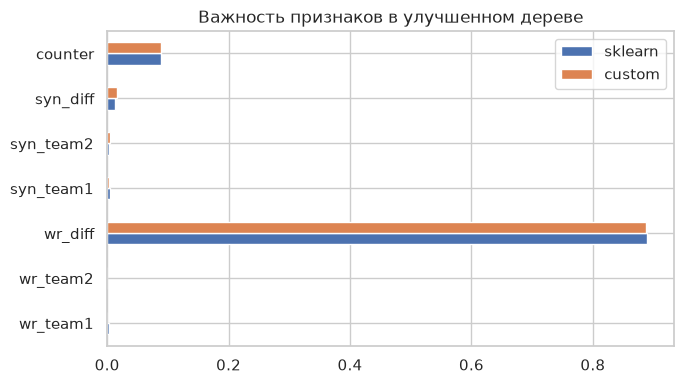

In [18]:
importances = pd.DataFrame({
    "sklearn": improved_cls.named_steps["model"].feature_importances_,
    "custom": custom_improved_cls.named_steps["model"].feature_importances_,
}, index=improved_cls.named_steps["features"].get_feature_names_out())
importances.plot.barh(figsize=(7, 4), title="Важность признаков в улучшенном дереве")
plt.tight_layout()

<!-- lab3_custom_improved -->
**Вывод.** С техниками улучшенного бейзлайна собственное дерево даёт ROC-AUC 0.638 (у `sklearn` 0.637) и тот же R² 0.9843 на шахматах. Небольшие различия в accuracy/F1 на Dota 2 (0.595 / 0.627 против 0.597 / 0.640) объясняются гистограммным поиском порогов: для непрерывных признаков драфта пороги берутся из 255 квантильных корзин, поэтому границы листьев и вероятности около 0.5 немного сдвигаются, что влияет на пороговые метрики. Важности признаков у обеих реализаций практически совпадают (главные — `wr_diff` и `counter`). Гистограммный подход ещё и быстрее: 0.19 с против 0.81 с у `sklearn`, которому приходится сортировать 92 тыс. непрерывных значений.

## 5. Итоги лабораторной работы

Сводная таблица всех вариантов; результаты сохраняются в `results/lab3.json`.

,roc_auc,accuracy,f1,fit_time,predict_time
variant,,,,,
sklearn baseline,0.5181,0.5193,0.5435,3.2355,0.0239
sklearn improved,0.6368,0.5966,0.6403,0.8094,0.0829
custom,0.5214,0.5222,0.5445,5.4783,0.0139
custom improved,0.6378,0.5951,0.6274,0.1903,0.0943


,r2,rmse,mae,fit_time,predict_time
variant,,,,,
sklearn baseline,0.9875,0.0559,0.0031,0.0099,0.0027
sklearn improved,0.9843,0.0625,0.0047,0.0218,0.0056
custom,0.9875,0.0559,0.0031,0.0074,0.0017
custom improved,0.9843,0.0625,0.0047,0.0271,0.0019


Сохранено: results/lab3.json


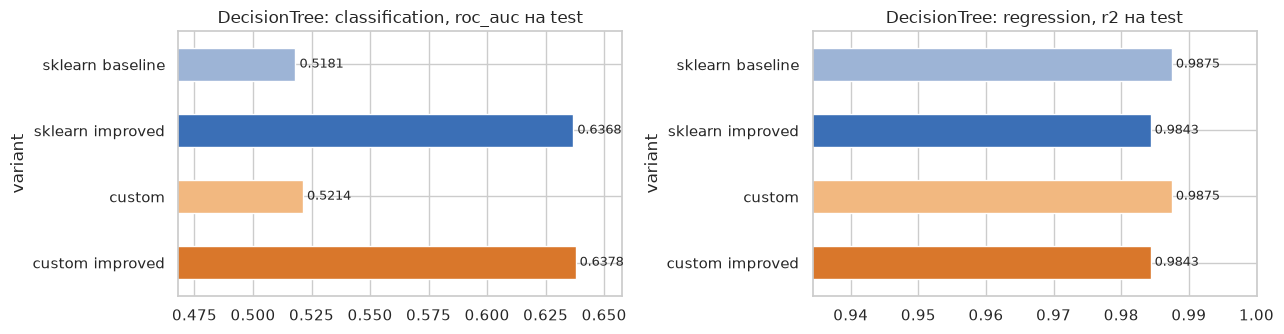

In [19]:
display(log.table("classification"), log.table("regression"))
log.plot()
print("Сохранено:", log.save().relative_to(ROOT))

<!-- lab3_summary -->
**Выводы по ЛР №3.**
1. Решающее дерево без ограничений катастрофически переобучается на шумной задаче (Dota 2, ROC-AUC 0.52), но идеально подходит для детерминированной логической задачи (шахматы, R² 0.99).
2. Для Dota 2 главный прирост дали признаки драфта (+0.085 ROC-AUC на CV) и регуляризация структуры дерева (глубина 6, крупные листья); критерий разбиения не важен. Итог на test: 0.518 → 0.637.
3. Для шахмат гипотезы об ограничении дерева и взаимодействиях признаков не подтвердились: оптимально полное дерево, улучшенный вариант статистически не отличается от бейзлайна.
4. Собственная реализация CART с гистограммным поиском разбиений воспроизводит `sklearn` точно на дискретных признаках и с точностью до квантования порогов — на непрерывных; она вдвое медленнее на глубоких деревьях, но быстрее на неглубоких.